In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Define o repositório

In [4]:
base = "drive/My Drive/Colab Notebooks"
repository = "junit4"

In [5]:
!pip install xgboost==1.0.0

     |████████████████████████████████| 109.8MB 68kB/s 
  Found existing installation: xgboost 0.90
    Uninstalling xgboost-0.90:
      Successfully uninstalled xgboost-0.90


Leitura dos dados do modelo

In [7]:
import pandas as pd

path = f"{base}/metadata/{repository}/modelo.csv"
data = pd.read_csv(path)

In [8]:
import numpy as np
from sklearn.model_selection import train_test_split
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

In [9]:
X = data[data.columns[1:-1]] 
y = data[data.columns[-1]] 
X.shape,y.shape

((6190, 20624), (6190,))

Normalização dos dados

In [10]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [11]:
X_train.shape, X_test.shape

((4952, 20624), (1238, 20624))

In [12]:
from sklearn import preprocessing
'''
parametros = {
    "learning_rate": [0.01,0.03,1],
    "max_depth": [5,7,10],
    "n_estimators": [10,50,100,200,500]
}
'''
parametros = {
    "learning_rate": [0.01, 0.03,1],
    "max_depth": [5,7,10],
    "n_estimators": [10,50,100,200]
}

Vetor de respostas

In [ ]:
#min cv=5
#cv = GridSearchCV(xgb.XGBRegressor(), parametros, cv=10, n_jobs=-1, verbose=True)
cv = GridSearchCV(xgb.XGBRegressor(), parametros, cv=3, n_jobs=-1, verbose=True)
cv.fit(X,y)

Fitting 3 folds for each of 27 candidates, totalling 81 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
/usr/local/lib/python3.6/dist-packages/joblib/externals/loky/process_executor.py:691: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  "timeout or by a memory leak.", UserWarning
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed: 99.4min
[Parallel(n_jobs=-1)]: Done  81 out of  81 | elapsed: 193.0min finished


[13:14:23] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.


GridSearchCV(cv=3, error_score=nan,
             estimator=XGBRegressor(base_score=0.5, booster='gbtree',
                                    colsample_bylevel=1, colsample_bynode=1,
                                    colsample_bytree=1, gamma=0,
                                    importance_type='gain', learning_rate=0.1,
                                    max_delta_step=0, max_depth=3,
                                    min_child_weight=1, missing=None,
                                    n_estimators=100, n_jobs=1, nthread=None,
                                    objective='reg:linear', random_state=0,
                                    reg_alpha=0, reg_lambda=1,
                                    scale_pos_weight=1, seed=None, silent=None,
                                    subsample=1, verbosity=1),
             iid='deprecated', n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.03, 1],
                         'max_depth': [5, 7, 10],
                         

Obtém os melhores parâmetros e estimadores

In [ ]:
bestmodel = cv.best_estimator_
bestparams = cv.best_params_
bestparams

{'learning_rate': 1, 'max_depth': 7, 'n_estimators': 100}

In [ ]:
#X_test = min_max_scaler.transform(X_test)
result = bestmodel.predict(X_test)

Verifica o erro

In [ ]:
from sklearn.metrics import mean_squared_error
mean_squared_error(y_test,result)
#refactoring-toy-example => 0.42260584847293786 || 0.42260584847293786
#gson => 3.6027717749822266 || 3.6027717749822266

0.1574895141408201

Armazena os dados do modelo treinado

In [ ]:
bestmodel.save_model(f"{base}/metadata/{repository}/modelo_treinado.json")

Ou a partir do modelo treinado externamente

In [13]:
import pandas as pd
import xgboost as xgb

bestmodel = xgb.XGBRegressor()
bestmodel.load_model(f"{base}/metadata/{repository}/modelo_treinado.json")

In [14]:
result = bestmodel.predict(X_test)

In [15]:
from sklearn.metrics import mean_squared_error
error = mean_squared_error(y_test,result)
print(f"Erro: {error}")
print(f"Erro percentual: {(error/abs(-4-4))*100}%")

Erro: 0.05637791301275048
Erro percentual: 0.7047239126593811%


Instalação da biblioteca Shap

In [16]:
!!pip install shap

['Collecting shap',
 '\x1b[?25l  Downloading https://files.pythonhosted.org/packages/d2/17/37ee6c79cafbd9bb7423b54e55ea90beec66aa7638664d607bcc28de0bae/shap-0.36.0.tar.gz (319kB)',
 '',
 '\x1b[K     |█                               | 10kB 18.3MB/s eta 0:00:01',
 '\x1b[K     |██                              | 20kB 1.6MB/s eta 0:00:01',
 '\x1b[K     |███                             | 30kB 1.9MB/s eta 0:00:01',
 '\x1b[K     |████                            | 40kB 2.2MB/s eta 0:00:01',
 '\x1b[K     |█████▏                          | 51kB 2.0MB/s eta 0:00:01',
 '\x1b[K     |██████▏                         | 61kB 2.2MB/s eta 0:00:01',
 '\x1b[K     |███████▏                        | 71kB 2.4MB/s eta 0:00:01',
 '\x1b[K     |████████▏                       | 81kB 2.6MB/s eta 0:00:01',
 '\x1b[K     |█████████▏                      | 92kB 2.8MB/s eta 0:00:01',
 '\x1b[K     |██████████▎                     | 102kB 2.7MB/s eta 0:00:01',
 '\x1b[K     |███████████▎                    | 112kB 2.7MB/s 

Inicialização da visualização JS

In [17]:
import shap

Criação do Explainer

In [18]:
explainer = shap.TreeExplainer(bestmodel)
shap_values = explainer.shap_values(X_train)

Geração do Gráfico de Força (Cada arquivo)

In [19]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[6,:], X_train.iloc[6,:])

Análise de Impacto das Modificações

In [20]:
modificacoes = bestmodel.get_booster().feature_names

Criar tabela de valores de cada modificação (vazia)

In [ ]:
from statistics import mean
from functools import reduce

tabela = {}
for modificacao in modificacoes:
  tabela[modificacao] = []

posicao = 0
for linha in X_train.values:
  conjunto = shap_values[posicao]
  pesos = list(map(lambda x: abs(x), filter(lambda x: x != 0, conjunto)))
  soma_total = reduce((lambda x,y: x+y), pesos)
  percentuais = list(map(lambda x: x/soma_total, pesos))
  if len(percentuais) > 0:
    percentuais_avg = mean(percentuais)

  contador = 0
  for item in linha:
    if item != 0:
      valor = shap_values[posicao][contador]
      #if valor != 0:
      modificacao = modificacoes[contador]
      percentual = abs(valor)/soma_total
      tabela[modificacao].append({
        "percentual": percentual,
        "acima_media": percentual >= percentuais_avg
      })

    contador = contador + 1
    
  posicao = posicao + 1

In [ ]:
#tabela

Calcular Impacto Médio de cada Padrão de Modificação

In [ ]:
result = {}
for modificacao,impactos in tabela.items():
  if len(impactos) > 0:
    #print(f"{modificacao}: {impactos}")
    result[modificacao] = mean(list(map(lambda x: x["percentual"], impactos)))

In [ ]:
#result

Impacto médio dos padrões de modificação com ocorrência >= 2

In [ ]:
import matplotlib.pyplot as plt

def plot(data, quantidade=None):
  fig = plt.gcf()
  fig.set_size_inches(12, 6.6)

  #data = {k: v for k, v in sorted(data.items(), key=lambda item: abs(item[1]), reverse=True)}
  #x = data.keys()
  #y = list(map(lambda x: abs(x), data.values()))

  data = {k: v for k, v in sorted(data.items(), key=lambda item: abs(item[1]), reverse=True)}
  if quantidade:
    x = list(data.keys())[:quantidade]
    y = list(map(lambda x: abs(x), data.values()))[:quantidade]
  else:
    x = data.keys()
    y = list(map(lambda x: abs(x), data.values()))

  
  p = plt.bar(x, y, orientation='vertical')

  plt.title("Percentual Médio de Impacto dos Padrões de Modificação")
  plt.ylabel("Impacto Médio nos Arquivos de Ocorrência")
  plt.xlabel("Padrões de Modificação")
  plt.xticks(rotation=45)

  plt.show()

Lista de Padrões das Modificações

In [ ]:
lista_padroes = ['#11255', '#7534', '#13841', '#4872', '#461', '#15705', '#14104', '#157', '#5221', '#5260', '#15703', '#5211', '#5215', '#15709', '#389', '#4522', '#6625', '#17134', '#2854', '#2844', '#16559', '#2884', '#2808', '#2860', '#7348', '#8694', '#9042', '#677', '#5464', '#6046', '#669', '#687', '#11236', '#673', '#17795', '#16560', '#17124', '#4632', '#3216', '#14603', '#11760', '#17139', '#12390', '#15861', '#10740', '#17792', '#19985', '#11500', '#4415', '#9037', '#2764', '#2767', '#2766', '#2771', '#13976', '#9335', '#4938', '#3031', '#8226', '#15945', '#15949', '#17909', '#16019', '#5158', '#5148', '#5151', '#16123', '#1282', '#3707', '#15903', '#16056', '#5509', '#4747', '#4742', '#12252', '#3469', '#8141', '#1846', '#15950', '#5152', '#6333', '#5510', '#6343', '#2019', '#3235', '#2015', '#1795', '#2005', '#1809', '#6332', '#5309', '#6346', '#4452', '#1938', '#5312', '#15943', '#5314', '#5119', '#4802', '#5356', '#2055', '#15946', '#12297', '#4616', '#4799', '#3457', '#15951', '#15948', '#417', '#4576', '#4618', '#5076', '#14290', '#2731', '#2795', '#11805', '#19153', '#5098', '#4403', '#11826', '#11836', '#2743', '#2584', '#4569', '#9020', '#12607', '#16204', '#2732', '#343', '#16196', '#4889', '#12598', '#12298', '#11809', '#11455', '#2761', '#18074', '#4451', '#1821', '#10267', '#1820', '#3465', '#5154', '#7963', '#7957', '#4935', '#2198', '#8635', '#13296', '#13166', '#18417', '#4795', '#12594', '#4803', '#12405', '#13299', '#6631', '#5153', '#10264', '#4924', '#8573', '#2343', '#4926', '#4948', '#13074', '#4947', '#4597', '#9044', '#1141', '#16077', '#1738', '#1430', '#2207', '#1408', '#4607', '#1958', '#4563', '#525', '#524', '#1074', '#1137', '#2765', '#13304', '#316', '#8194', '#3769', '#8945', '#649', '#6287', '#59', '#413', '#200', '#60', '#246', '#1908', '#6176', '#3657', '#6179', '#12075', '#6912', '#219', '#6180', '#11074', '#6182', '#6175', '#6195', '#8954', '#3386', '#4072', '#1423', '#2930', '#6183', '#12494', '#15728', '#15726', '#8946', '#9336', '#7917', '#8492', '#2271', '#1970', '#222', '#251', '#4751', '#1343', '#5690', '#5694', '#2668', '#6650', '#13397', '#502', '#582', '#6205', '#3844', '#4717', '#612', '#8952', '#3466', '#2653', '#2677', '#6651', '#8958', '#1123', '#421', '#13460', '#2650', '#16197', '#548', '#11001', '#1226', '#13366', '#3878', '#3880', '#571', '#1057', '#1641', '#11206', '#6966', '#1104', '#229', '#7921', '#4781', '#16454', '#2278', '#4721', '#4783', '#17702', '#1080', '#252', '#14465', '#527', '#1432', '#5481', '#15261', '#230', '#6197', '#531', '#1135', '#1419', '#11004', '#1058', '#2217', '#1826', '#14482', '#220', '#2663', '#218', '#3700', '#8817', '#232', '#4070', '#3773', '#14481', '#752', '#240', '#1335', '#12742', '#1067', '#14473', '#18168', '#530', '#1149', '#12435', '#245', '#4047', '#243', '#14470', '#12437', '#3760', '#11272', '#226', '#599', '#8270', '#1076', '#3764', '#1127', '#14467', '#1102', '#18249', '#3369', '#11077', '#1071', '#532', '#505', '#3659', '#248', '#250', '#227', '#6908', '#740', '#4620', '#2176', '#1122', '#1117', '#3772', '#228', '#4537', '#7106', '#106', '#1051', '#19270', '#26', '#18160', '#2234', '#107', '#5517', '#12226', '#1059', '#18484', '#3207', '#18312', '#3896', '#14279', '#31', '#7329', '#15228', '#6658', '#1063', '#3310', '#4907', '#1056', '#10297', '#8523', '#3941', '#8615', '#6968', '#1140', '#8068', '#12016', '#14287', '#3471', '#1050', '#18567', '#14284', '#3294', '#16700', '#14166', '#10048', '#4909', '#1148', '#14163', '#19273', '#20052', '#1054', '#3463', '#1047', '#4893', '#14294', '#14752', '#3468', '#10384', '#1421', '#13594', '#3472', '#9916', '#12014', '#13604', '#7594', '#28', '#2992', '#5628', '#16188', '#6914', '#5861', '#20104', '#9193', '#7544', '#18272', '#7243', '#1170', '#19888', '#17339', '#10282', '#8607', '#20047', '#18287', '#11124', '#18307', '#2510', '#15997', '#20015', '#14315', '#1177', '#8349', '#19901', '#18942', '#8629', '#3474', '#2641', '#3470', '#9981', '#20407', '#4782', '#15636', '#2975', '#18193', '#20050', '#18013', '#4986', '#1424', '#6799', '#3153', '#7897', '#12188', '#10813', '#355', '#3117', '#17673', '#11437', '#7879', '#16461', '#7073', '#5433', '#18474', '#5862', '#18012', '#7005', '#18471', '#18415', '#9736', '#16708', '#14330', '#12007', '#5826', '#8626', '#8788', '#6953', '#18234', '#18202', '#20073', '#65', '#17189', '#14365', '#1228', '#3473', '#17040', '#19815', '#10024', '#5484', '#4528', '#6796', '#14295', '#6999', '#14292', '#6990', '#13955', '#17042', '#16179', '#6177', '#9445', '#4060', '#18261', '#18604', '#10254', '#16455', '#4988', '#1462', '#13073', '#19303', '#14278', '#12183', '#18444', '#4789', '#18274', '#8731', '#720', '#16593', '#17041', '#18430', '#14289', '#18226', '#7010', '#8924', '#4994', '#14281', '#18478', '#14758', '#11581', '#18324', '#3157', '#15643', '#10792', '#18129', '#14141', '#15776', '#4068', '#10521', '#17667', '#10533', '#3504', '#18293', '#20072', '#12455', '#15838', '#18388', '#14291', '#14756', '#15130', '#17347', '#5863', '#4214', '#15138', '#15357', '#18233', '#6798', '#20292', '#18201', '#18963', '#18450', '#4823', '#6915', '#11443', '#10672', '#2647', '#18406', '#19814', '#19139', '#2191', '#6250', '#7384', '#17895', '#18369', '#10295', '#19904', '#18262', '#10404', '#1185', '#5642', '#8786', '#15362', '#10028', '#10058', '#19636', '#14442', '#12097', '#253', '#2534', '#8939', '#18237', '#18128', '#8598', '#4067', '#9197', '#4058', '#1081', '#962', '#18243', '#5242', '#221', '#1136', '#5580', '#5577', '#18164', '#5504', '#1143', '#5811', '#5500', '#13691', '#12562', '#9179', '#1073', '#1069', '#1138', '#8614', '#1144', '#5760', '#526', '#9181', '#18140', '#9004', '#4786', '#9178', '#9186', '#18135', '#8751', '#8905', '#18399', '#11942', '#18614', '#9188', '#18612', '#18617', '#18148', '#19811', '#9194', '#18396', '#9190', '#9192', '#9195', '#1834', '#4492', '#2117', '#13461', '#3879', '#3889', '#14150', '#3044', '#9848', '#7780', '#5526', '#5202', '#2781', '#5448', '#64', '#8154', '#2777', '#1740', '#18149', '#13818', '#5231', '#11744', '#18269', '#3872', '#19438', '#11745', '#6090', '#13634', '#11713', '#11882', '#18480', '#18358', '#18119', '#5259', '#8088', '#18464', '#18352', '#11702', '#18145', '#11700', '#18141', '#18219', '#18147', '#19819', '#11739', '#9223', '#1060', '#1107', '#1115', '#4701', '#1089', '#7945', '#8404', '#4702', '#9495', '#956', '#4364', '#12488', '#16751', '#4365', '#4367', '#14654', '#5233', '#4366', '#2931', '#5223', '#1741', '#1752', '#1744', '#1663', '#8402', '#8710', '#9395', '#19483', '#8702', '#289', '#949', '#2563', '#12129']

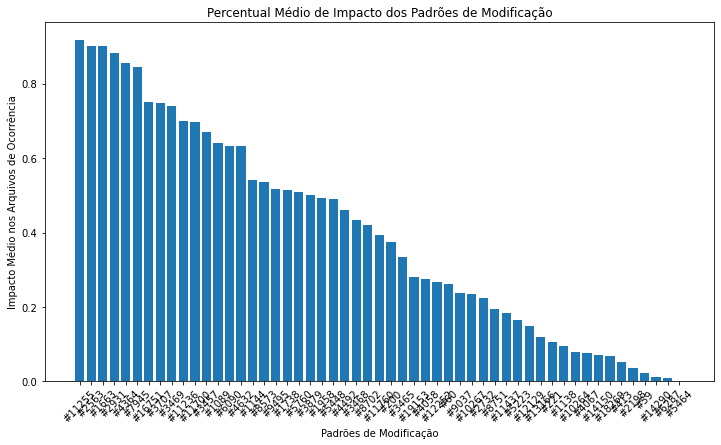

In [ ]:
impacto_padroes = {}
for padrao in lista_padroes:
  if padrao in result and result[padrao] > 0:
    impacto_padroes[padrao] = result[padrao]

plot(impacto_padroes)

Frequência de Impacto acima da média das modificações do mesmo arquivo

In [ ]:
ocorrencias = {}
for modificacao,items in tabela.items():
  size = len(items)
  contagem = 0
  if size > 0 and modificacao in lista_padroes:
    for item in items:
      if item["acima_media"]:
        contagem = contagem + 1
    ocorrencias[modificacao] = {
      "taxa": contagem/size,
      "tamanho": size
    }

In [ ]:
#ocorrencias

In [ ]:
ocorrencias_filtradas = {}
for modificacao,dados in ocorrencias.items():
  if dados['tamanho'] > 1 and dados['taxa'] > 0:
    ocorrencias_filtradas[modificacao] = dados['taxa']

In [ ]:
import matplotlib.pyplot as plt

def plot_percentual(data, quantidade=None):
  fig = plt.gcf()
  fig.set_size_inches(12, 6.6)

  #data = {k: v for k, v in sorted(data.items(), key=lambda item: abs(item[1]), reverse=True)}
  #x = data.keys()
  #y = list(map(lambda x: abs(x), data.values()))

  data = {k: v for k, v in sorted(data.items(), key=lambda item: abs(item[1]), reverse=True)}
  if quantidade:
    x = list(data.keys())[:quantidade]
    y = list(map(lambda x: abs(x), data.values()))[:quantidade]
  else:
    x = data.keys()
    y = list(map(lambda x: abs(x), data.values()))

  
  p = plt.bar(x, y, orientation='vertical')

  plt.title("Frequência de Impacto Acima da Média dos Padrões de Modificação")
  plt.ylabel("Frequência da Impacto Superior a Média do Arquivo")
  plt.xlabel("Padrões de Modificação")
  plt.xticks(rotation=45)

  plt.show()

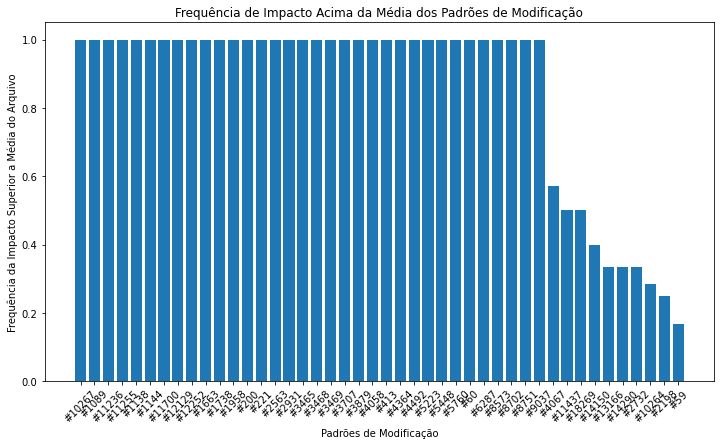

In [ ]:
plot_percentual(ocorrencias_filtradas)

Verificando a predominância do tipo de modificação nos arquivos que ocorrem os principais padrões

In [ ]:
importantes = impacto_padroes
#print(importantes)

Análise de ocorrência das principais modificações

In [ ]:
ocorrencia_modificacoes_arquivo = []
i = 0
for linha in X_train.values:
  conjunto = {
    'resultado': y_train.values[i],
    'arquivos': {}
  }
  j = 0
  for item in linha:
    if item == 1 or item == -1:
      modificacao = modificacoes[j]
      conjunto["arquivos"][modificacao] = shap_values[i][j]
    j = j + 1
  ocorrencia_modificacoes_arquivo.append(conjunto)
  i = i + 1
  

In [ ]:
arquivos_com_principais_modificacoes = []
for ocorrencia in ocorrencia_modificacoes_arquivo:
  for item in importantes:
    if item in ocorrencia['arquivos'].keys():
      arquivos_com_principais_modificacoes.append(ocorrencia)
      break

In [ ]:
arquivos_percentuais = []
for item in arquivos_com_principais_modificacoes:
  soma = 0
  for num in list(item['arquivos'].values()):
    soma = soma + num
  if item['resultado'] != soma and soma != 0:
    proporcao = item['resultado']/soma
    #print(item['resultado'], soma, proporcao)
    novo = {
        'resultado': item['resultado'],
        'arquivos': {}
    }
    for arquivo,peso in item['arquivos'].items():
      #print(peso,proporcao)
      novo['arquivos'][arquivo] = peso*proporcao
    arquivos_percentuais.append(novo)

  else:
    arquivos_percentuais.append(item)


In [ ]:
metricas_modificacoes = {}

In [ ]:
for item in arquivos_percentuais:
  for modificacao,peso in item['arquivos'].items():
    if modificacao in metricas_modificacoes:
      metricas_modificacoes[modificacao].append(peso)
    else:
      metricas_modificacoes[modificacao] = [peso]

In [ ]:
lista_avaliacoes = {}
for key,value in metricas_modificacoes.items():
  if key in importantes:
    lista_avaliacoes[key] = value

In [ ]:
from google.colab import files

def plot_box(keys, values):
    fig, ax = plt.subplots()
    bp = ax.boxplot(
        values, 
        sym='k+'
    )

    ax.set_xlabel('Code pattern')
    ax.set_ylabel('Distribution of Maintainability Impact')
    plt.setp(bp['whiskers'], color='k', linestyle='-')
    plt.setp(bp['fliers'], markersize=3.0)
    #plt.title("Distribuição de Manutenabilidade por Padrão de Modificação")

    plt.xticks(np.arange(len(keys))+1, keys, rotation=55)
    fig.set_size_inches(15, 8)
    plt.savefig("boxplot-padroes.pdf",  bbox_inches='tight')
    files.download("boxplot-padroes.pdf")

In [ ]:
len(list(lista_avaliacoes.keys()))

53

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

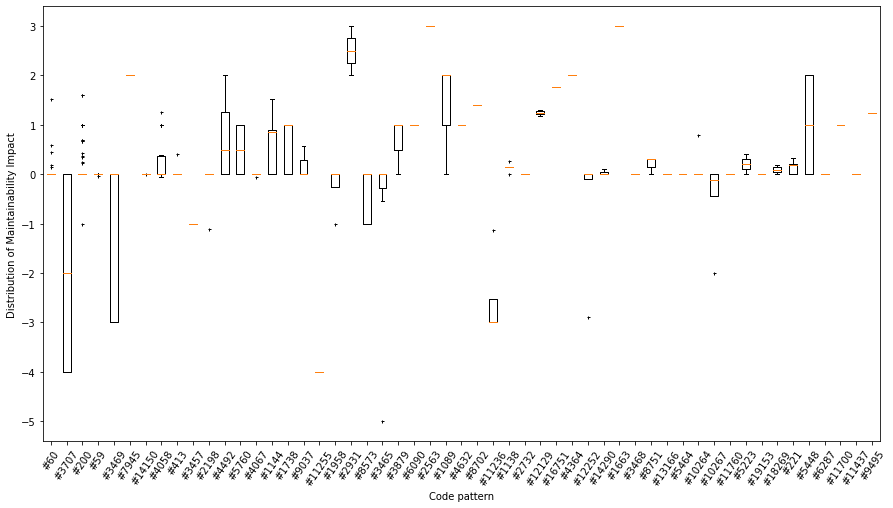

In [ ]:
plot_box(lista_avaliacoes.keys(),lista_avaliacoes.values())

In [ ]:
print(list(lista_avaliacoes.keys()))

['#60', '#3707', '#200', '#59', '#3469', '#14150', '#4058', '#413', '#2198', '#4492', '#5760', '#4067', '#1144', '#1738', '#9037', '#11255', '#1958', '#2931', '#8573', '#3465', '#3879', '#2563', '#1089', '#8702', '#11236', '#1138', '#2732', '#12129', '#4364', '#12252', '#14290', '#1663', '#3468', '#8751', '#13166', '#10264', '#10267', '#5223', '#18269', '#221', '#5448', '#6287', '#11700', '#11437']


Matriz de correlação entre os principais padrões

In [ ]:
!!pip install ppscore

['Collecting ppscore',
 '  Downloading https://files.pythonhosted.org/packages/90/df/b4ae18f31e2be37d81fa9956774bd192c0d3f759885f3b1974024bb37faa/ppscore-1.1.1.tar.gz',
 'Requirement already satisfied: pandas<2.0.0,>=1.0.0 in /usr/local/lib/python3.6/dist-packages (from ppscore) (1.1.2)',
 'Requirement already satisfied: scikit-learn<1.0.0,>=0.20.2 in /usr/local/lib/python3.6/dist-packages (from ppscore) (0.22.2.post1)',
 'Requirement already satisfied: python-dateutil>=2.7.3 in /usr/local/lib/python3.6/dist-packages (from pandas<2.0.0,>=1.0.0->ppscore) (2.8.1)',
 'Requirement already satisfied: numpy>=1.15.4 in /usr/local/lib/python3.6/dist-packages (from pandas<2.0.0,>=1.0.0->ppscore) (1.18.5)',
 'Requirement already satisfied: pytz>=2017.2 in /usr/local/lib/python3.6/dist-packages (from pandas<2.0.0,>=1.0.0->ppscore) (2018.9)',
 'Requirement already satisfied: scipy>=0.17.0 in /usr/local/lib/python3.6/dist-packages (from scikit-learn<1.0.0,>=0.20.2->ppscore) (1.4.1)',
 'Requirement 

In [ ]:
import ppscore as pps

Correlação entre duas modificações

In [ ]:
nova_tabela = pd.DataFrame(data=shap_values, columns=modificacoes)
#nova_tabela = pd.DataFrame(data=shap_values)

In [ ]:
#nova_tabela

In [ ]:
colunas = list(lista_avaliacoes.keys())

In [ ]:
tabela_filtrada = nova_tabela[colunas]

In [ ]:
#pps.matrix(tabela_filtrada)

In [ ]:
  !!pip install seaborn

['Requirement already satisfied: seaborn in /usr/local/lib/python3.6/dist-packages (0.11.0)',
 'Requirement already satisfied: matplotlib>=2.2 in /usr/local/lib/python3.6/dist-packages (from seaborn) (3.2.2)',
 'Requirement already satisfied: scipy>=1.0 in /usr/local/lib/python3.6/dist-packages (from seaborn) (1.4.1)',
 'Requirement already satisfied: numpy>=1.15 in /usr/local/lib/python3.6/dist-packages (from seaborn) (1.18.5)',
 'Requirement already satisfied: pandas>=0.23 in /usr/local/lib/python3.6/dist-packages (from seaborn) (1.1.2)',
 'Requirement already satisfied: pyparsing!=2.0.4,!=2.1.2,!=2.1.6,>=2.0.1 in /usr/local/lib/python3.6/dist-packages (from matplotlib>=2.2->seaborn) (2.4.7)',
 'Requirement already satisfied: python-dateutil>=2.1 in /usr/local/lib/python3.6/dist-packages (from matplotlib>=2.2->seaborn) (2.8.1)',
 'Requirement already satisfied: kiwisolver>=1.0.1 in /usr/local/lib/python3.6/dist-packages (from matplotlib>=2.2->seaborn) (1.2.0)',
 'Requirement already 

In [ ]:
import seaborn as sns

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

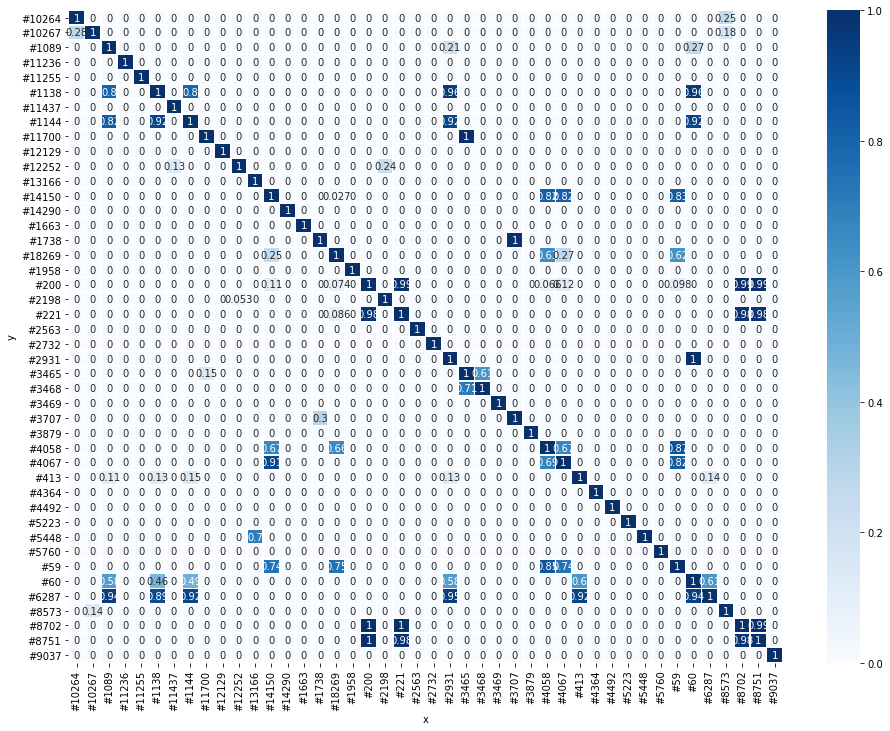

In [ ]:
import matplotlib.pyplot as plt

matrix_df = pps.matrix(tabela_filtrada)[['x', 'y', 'ppscore']].pivot(columns='x', index='y', values='ppscore')
plt.figure(figsize = (16,12))

sns.heatmap(matrix_df, vmin=0, vmax=1, cmap="Blues", linewidths=0.5, annot=True)
plt.savefig("matriz.pdf",  bbox_inches='tight')
files.download("matriz.pdf")

Verificação dos tipos de modificação que ocorrem juntamente com as principais modificações

In [21]:
principais_modificacoes = ['#10264', '#10267', '#1089', '#11236', '#11255', '#1138', '#11437', '#1144', '#11700', '#12129', '#12252', '#13166', '#14150', '#14290', '#1663', '#1738', '#18269', '#1958', '#200', '#2198', '#221', '#2563', '#2732', '#2931', '#3465', '#3468', '#3469', '#3707', '#3879', '#4058', '#4067', '#413', '#4364', '#4492', '#5223', '#5448', '#5760', '#59', '#60', '#6287', '#8573', '#8702', '#8751', '#9037']

In [22]:
resumo = {}

for modificacao in principais_modificacoes:
  resumo[modificacao] = []

i = 0
for linha in X_train.values:
  j = 0
  modificacoes_linha = []
  for item in linha:
    if item != 0:
      modificacao = modificacoes[j]
      modificacoes_linha.append(modificacao)
    j = j + 1
  
  if len(modificacoes_linha) > 0:
    for principal in principais_modificacoes:
      if principal in modificacoes_linha:
        resumo[principal].append(modificacoes_linha)
  
  i = i + 1

Função de leitura de arquivo ZIP

In [23]:
#ler arquivo zip
import zipfile
import json

#multipattern_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/multipattern.zip", "r")
def read_file_from_zip(zipfile, file):
  data = zipfile.read(file)
  return json.loads(data.decode("utf-8"))

In [24]:
clusters_zip = zipfile.ZipFile(f"{base}/metadata/{repository}/clusters.zip","r")
#read_file_from_zip(clusters_zip, f"clusters/#3.json")

In [25]:
dados = {}
temporario = {}
for modificacao, listas in resumo.items():
  dados[modificacao] = []

  for lista in listas:
    conjunto = []
    for numero in lista:
      #if numero != modificacao:
      if numero in temporario:
        tipo = temporario[numero]
      else:
        arquivo = read_file_from_zip(clusters_zip, f"clusters/{numero}.json")
        tipos = []
        for elemento in arquivo['base']['items']:
          tipos.append(elemento['type'])
        if "update" in tipos:
          tipo = "update"
        elif "move" in tipos:
          tipo = "move"
        elif "insert" in tipos:
          tipo = "insert"
        else:
          tipo = "delete"

      conjunto.append(tipo)
    dados[modificacao].append(conjunto)


In [26]:
resultado = {}
for modificacao, listagem in dados.items():
  elemento = {
      "arquivos": len(listagem),
      "modificacoes_por_arquivo": [],
      "tipos": {
          "insert": 0,
          "delete": 0,
          "move": 0,
          "update": 0
      }
  }

  for lista in listagem:
    elemento["modificacoes_por_arquivo"].append(len(lista))
    for item in lista:
      elemento["tipos"][item] = elemento["tipos"][item] + 1

  elemento["media"] = 0;
  for item in elemento["modificacoes_por_arquivo"]:
    elemento["media"] = elemento["media"] + item;
  elemento["media"] = elemento["media"]/elemento["arquivos"];
  
  resultado[modificacao] = elemento



In [27]:
resultado

{'#10264': {'arquivos': 7,
  'media': 8.428571428571429,
  'modificacoes_por_arquivo': [2, 10, 4, 15, 9, 6, 13],
  'tipos': {'delete': 16, 'insert': 14, 'move': 5, 'update': 24}},
 '#10267': {'arquivos': 5,
  'media': 9.8,
  'modificacoes_por_arquivo': [2, 10, 15, 9, 13],
  'tipos': {'delete': 14, 'insert': 13, 'move': 1, 'update': 21}},
 '#1089': {'arquivos': 3,
  'media': 17.666666666666668,
  'modificacoes_por_arquivo': [16, 21, 16],
  'tipos': {'delete': 20, 'insert': 18, 'move': 8, 'update': 7}},
 '#11236': {'arquivos': 4,
  'media': 1.75,
  'modificacoes_por_arquivo': [1, 1, 4, 1],
  'tipos': {'delete': 0, 'insert': 0, 'move': 0, 'update': 7}},
 '#11255': {'arquivos': 4,
  'media': 1.0,
  'modificacoes_por_arquivo': [1, 1, 1, 1],
  'tipos': {'delete': 0, 'insert': 0, 'move': 0, 'update': 4}},
 '#1138': {'arquivos': 5,
  'media': 22.8,
  'modificacoes_por_arquivo': [29, 20, 28, 20, 17],
  'tipos': {'delete': 14, 'insert': 53, 'move': 10, 'update': 37}},
 '#11437': {'arquivos': 2,


Média de modificações nos arquivos que contém as ocorrências dos padrões

In [28]:
total = 0
items = list(resultado.values())
for item in items:
  total = total + item["media"]

print(f"Média: {total/len(items)}")

Média: 12.613225575071022


Relação de mapeamentos de inserção/deleção por update/move

In [29]:
total = 0
print(list(resultado.keys()))
items = list(resultado.values())
for item in items:
  tipo = item["tipos"]
  valor = ((tipo["insert"]+tipo["delete"])/(tipo["update"]+tipo["move"]))
  print(valor)
  total = total + valor


['#10264', '#10267', '#1089', '#11236', '#11255', '#1138', '#11437', '#1144', '#11700', '#12129', '#12252', '#13166', '#14150', '#14290', '#1663', '#1738', '#18269', '#1958', '#200', '#2198', '#221', '#2563', '#2732', '#2931', '#3465', '#3468', '#3469', '#3707', '#3879', '#4058', '#4067', '#413', '#4364', '#4492', '#5223', '#5448', '#5760', '#59', '#60', '#6287', '#8573', '#8702', '#8751', '#9037']
1.0344827586206897
1.2272727272727273
2.533333333333333
0.0
0.0
1.425531914893617
0.0
1.2876712328767124
3.9545454545454546
1.5555555555555556
1.391304347826087
3.0434782608695654
1.3333333333333333
0.15384615384615385
0.5
0.5625
0.3548387096774194
0.0
0.7579365079365079
0.9795918367346939
0.37962962962962965
4.333333333333333
3.6363636363636362
0.0
0.5217391304347826
0.5789473684210527
0.0
0.0
0.6666666666666666
0.37383177570093457
0.22058823529411764
0.449438202247191
1.25
1.0666666666666667
1.75
1.6666666666666667
3.0
0.5281954887218046
0.6061946902654868
0.8888888888888888
0.0
3.83333333

In [30]:
print(f"Média: {total/len(items)}")

Média: 1.162727080778222
